In [1]:
import numpy as np
import matplotlib.pyplot as plt
from optical_transmission_system.components import *

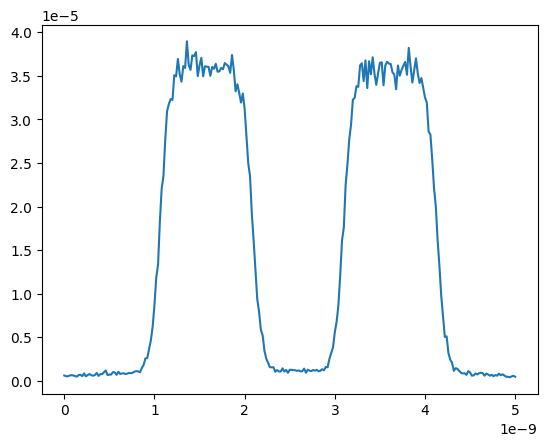

In [2]:
dac = System(components=[
    NRZEncoder(sampling_rate=50e9),
    ElectricalLowPassFilter(order=5, cutoff_frequency=3e9)
])

modulator = System(components=[
    PulseAmplitudeModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128),
        order=1
    ),
    AWGN(level=-15.0)
])

system = System(components=[
    dac,
    modulator,
    OpticalChannel(attenuation=0.22, length=80, chromatic_dispersion=17),
])

input_signal = Signal.digital(samples=np.array([0, 1, 0, 1, 0]), data_rate=1e9)
output_signal = system(input_signal)

plt.plot(output_signal.timing.time, np.sum(output_signal.samples**2, axis=1))

In [3]:
np.sum(output_signal.samples**2) / len(output_signal.samples)

np.float64(1.5175535242747282e-05)

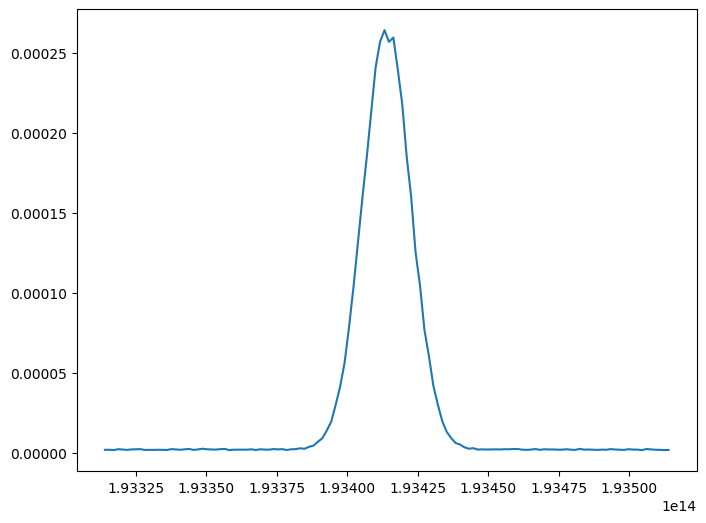

In [4]:
plt.figure(figsize=(8, 6))
plt.plot(output_signal.frequencies, np.sum(output_signal.samples.transpose()**2, axis=1))